In [1]:
import pandas as pd

df = pd.read_csv("listings.csv.gz")
print(df.shape)
df.head()

(29918, 90)


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,1352055619826961511,https://www.airbnb.com/rooms/1352055619826961511,20260914002229,2026-09-14,NaN,"New 3 bed, 1.5 bath",This stylish place to stay is perfect for grou...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,677651543,...,NaN,NaN,NaN,NaN,NaN,1,1,0,0,NaN
1,1215930899551057941,https://www.airbnb.com/rooms/1215930899551057941,20260914002229,2026-09-14,NaN,Queens apartament,Bring the whole family to this great place wit...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,392517036,...,NaN,NaN,NaN,NaN,NaN,1,0,1,0,NaN
2,1203866180302079266,https://www.airbnb.com/rooms/1203866180302079266,20260914002229,2026-09-15,NaN,Luxury Meets Comfort Stay NYC,This stylish place is close to must-see destin...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,115082911,...,NaN,NaN,NaN,NaN,NaN,2,0,2,0,NaN
3,15310580,https://www.airbnb.com/rooms/15310580,20260914002229,2026-09-15,previous scrape,Nice apartment in Gramercy.,Nice apartment in one of the best neighbors of NY,NaN,https://a0.muscache.com/pictures/c2c78aad-78c9...,27336207,...,4.88,5.00,4.25,NaN,NaN,2,2,0,0,0.07
4,32842295,https://www.airbnb.com/rooms/32842295,20260914002229,2026-09-15,previous scrape,Beautiful bedroom and full bathroom,NaN,NaN,https://a0.muscache.com/pictures/b946d6e3-07d6...,233227636,...,4.89,4.78,4.75,NaN,NaN,1,0,1,0,0.40


In [2]:
pd.set_option("display.max_rows", 100)

summary = pd.DataFrame({
    "dtype": df.dtypes,
    "missing_%": (df.isna().mean() * 100).round(1),
    "example": df.iloc[0]
})
summary

,dtype,missing_%,example
id,int64,0.0,1352055619826961511
listing_url,object,0.0,https://www.airbnb.com/rooms/1352055619826961511
scrape_id,int64,0.0,20260914002229
last_scraped,object,0.0,2026-09-14
source,object,70.2,NaN
name,object,0.0,"New 3 bed, 1.5 bath"
description,object,0.5,This stylish place to stay is perfect for grou...
neighborhood_overview,float64,100.0,NaN
picture_url,object,0.0,https://a0.muscache.com/pictures/miso/Hosting-...
host_id,int64,0.0,677651543


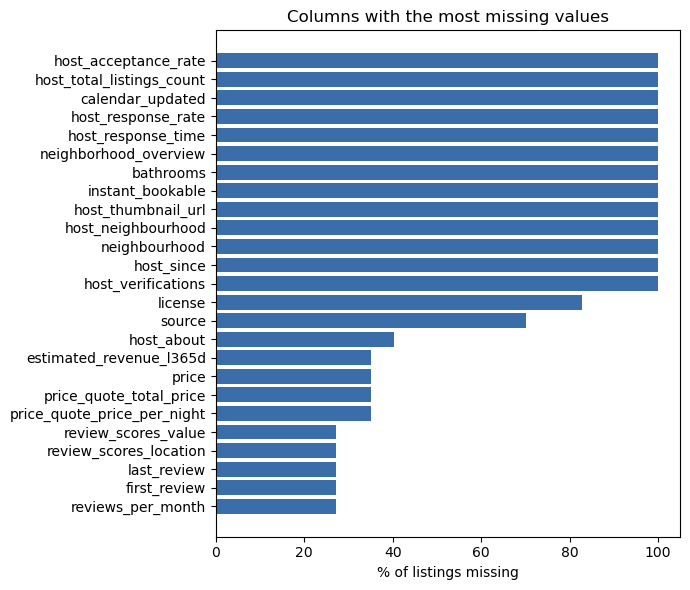

In [25]:
# Figure 1: columns with the most missing values (all 90 original columns)
import matplotlib.pyplot as plt

top = summary["missing_%"].sort_values(ascending=False).head(25)[::-1]   # 25 worst, biggest at top
plt.figure(figsize=(7, 6))
plt.barh(top.index, top.values, color="#3B6EA8")
plt.xlabel("% of listings missing")
plt.title("Columns with the most missing values")
plt.tight_layout()
plt.savefig("fig_missing.png")
plt.show()

In [3]:
summary.to_csv("column_summary.csv")

In [4]:
keep = [
    "id",
    "neighbourhood_group_cleansed", "neighbourhood_cleansed", "latitude", "longitude",
    "property_type", "room_type", "accommodates", "bedrooms", "beds",
    "bathrooms", "bathrooms_text", "amenities",
    "price", "minimum_nights", "maximum_nights", "license",
    "availability_365", "number_of_reviews", "number_of_reviews_ltm",
    "reviews_per_month", "estimated_occupancy_l365d", "last_review",
    "review_scores_rating", "review_scores_cleanliness",
    "review_scores_location", "review_scores_value",
    "host_is_superhost", "calculated_host_listings_count", "hosts_time_as_host_years"
]

df_small = df[keep].copy()
print(df_small.shape)


(29918, 30)


In [7]:
missing = (df_small.isna().mean() * 100).round(1).sort_values(ascending=False)
missing[missing > 0]

bathrooms                    100.0
license                       82.9
price                         35.1
review_scores_value           27.2
review_scores_location        27.2
reviews_per_month             27.1
review_scores_cleanliness     27.1
review_scores_rating          27.1
last_review                   27.1
beds                           3.9
bathrooms_text                 0.4
bedrooms                       0.1
dtype: float64

In [8]:
# Cleaning decision 1: drop 'bathrooms' (100% empty; info is in bathrooms_text)
df_small = df_small.drop(columns=["bathrooms"])
print(df_small.shape)

(29918, 29)


In [9]:
# Are any listings repeated?
print("Duplicate IDs:", df_small["id"].duplicated().sum())
print("Duplicate rows:", df_small.drop(columns=["id"]).duplicated().sum())

Duplicate IDs: 0
Duplicate rows: 230


In [10]:
# Look at the "duplicates": same host, identical units
dups = df_small.drop(columns=["id"]).duplicated(keep=False)
df.loc[dups[dups].index, ["host_id", "name", "room_type", "neighbourhood_cleansed", "price", "number_of_reviews"]].head(10)

,host_id,name,room_type,neighbourhood_cleansed,price,number_of_reviews
154,572649285,Amazing Bedroom Upper Manhattan,Private room,Harlem,$56.17,0
723,674226734,Standard Private Room,Private room,Crown Heights,$73.61,0
728,124028462,"Bright Room | Walk to Subway, Historic Sights",Private room,Bedford-Stuyvesant,$57.17,0
775,25138314,Relax and Unwind! 3 Units Close to Times Square!,Private room,Midtown,"$1,720.46",0
777,494285165,Central Midtown Room with Private Bath,Private room,Midtown,$89.15,0
908,533074450,Upper Manhattan Bedroom NYC,Private room,Harlem,$61.98,0
1200,576488520,Bold flavors & cocktails at Tuti Lounge & Bar,Private room,Midtown,NaN,0
1443,107434423,"Blueground | Nolita, washer/dryer, nr Bowery",Entire home/apt,Nolita,NaN,0
1447,494285165,Private Room in Chelsea,Private room,Chelsea,$99.10,0
1454,494285165,Modern Room in Chelsea,Private room,Chelsea,$99.10,0


In [11]:
# Cleaning decision 3: convert price from text ("$1,720.46") to a number (1720.46)
df_small["price"] = pd.to_numeric(df_small["price"].str.replace(r"[$,]", "", regex=True))
df_small["price"].describe()


count    19406.000000
mean       310.165607
std        574.094115
min         17.700000
25%        103.682500
50%        182.445000
75%        337.000000
max      31537.820000
Name: price, dtype: float64

In [12]:
# How many listings have extreme prices?
print("Over $2,000/night:", (df_small["price"] > 2000).sum())
print("Over $10,000/night:", (df_small["price"] > 10000).sum())
df_small.loc[df_small["price"] > 10000, ["room_type", "neighbourhood_cleansed", "accommodates", "price"]]

Over $2,000/night: 194
Over $10,000/night: 10


,room_type,neighbourhood_cleansed,accommodates,price
325,Entire home/apt,Midtown,16,12045.03
1952,Private room,Gramercy,6,10988.00
2455,Private room,Midtown,2,12217.60
4684,Entire home/apt,Tribeca,14,31537.82
9747,Private room,Murray Hill,2,12279.07
9946,Hotel room,Upper East Side,5,16630.00
10299,Hotel room,Upper East Side,5,16630.00
10345,Hotel room,Upper East Side,3,10461.00
15926,Entire home/apt,Midtown,16,12045.03
23992,Private room,Longwood,1,11028.87


In [13]:
# Cleaning decision 4: prices over $10,000/night are errors -> set to missing
import numpy as np
df_small.loc[df_small["price"] > 10000, "price"] = np.nan
print("Max price now:", df_small["price"].max())
print("Listings with a price:", df_small["price"].notna().sum())

Max price now: 10000.0
Listings with a price: 19396


In [14]:
# Minimum and maximum stay lengths
print(df_small["minimum_nights"].describe())
print("min nights > 365:", (df_small["minimum_nights"] > 365).sum())
print("max nights > 1125:", (df_small["maximum_nights"] > 1125).sum())
print("% with min stay >= 30 nights:", round((df_small["minimum_nights"] >= 30).mean() * 100, 1))

count    29910.000000
mean        26.784219
std         28.473399
min          1.000000
25%         30.000000
50%         30.000000
75%         30.000000
max       1124.000000
Name: minimum_nights, dtype: float64
min nights > 365: 16
max nights > 1125: 31
% with min stay >= 30 nights: 80.7


In [15]:
# Cleaning decision 5: cap impossible stay lengths, fill 8 missing with the median (30)
df_small["minimum_nights"] = df_small["minimum_nights"].fillna(df_small["minimum_nights"].median()).clip(upper=365)
df_small["maximum_nights"] = df_small["maximum_nights"].clip(upper=1125)
print("min nights now:", df_small["minimum_nights"].min(), "to", df_small["minimum_nights"].max())
print("missing:", df_small["minimum_nights"].isna().sum())

min nights now: 1.0 to 365.0
missing: 0


In [16]:
# Cleaning decision 6: missing review info = listing has no reviews yet (not an error)
df_small["has_reviews"] = df_small["number_of_reviews"] > 0
df_small["reviews_per_month"] = df_small["reviews_per_month"].fillna(0)
print(df_small["has_reviews"].value_counts())


has_reviews
True     21804
False     8114
Name: count, dtype: int64


In [17]:
# Cleaning decision 7: fill small gaps with the median for the same room type
for col in ["beds", "bedrooms"]:
    df_small[col] = df_small[col].fillna(df_small.groupby("room_type")[col].transform("median"))
print(df_small[["beds", "bedrooms"]].isna().sum())

beds        0
bedrooms    0
dtype: int64


In [18]:
# Preprocessing 1: "1.5 shared baths" -> bathrooms_num = 1.5, bathroom_shared = True
bt = df_small["bathrooms_text"].fillna("").str.lower()
df_small["bathrooms_num"] = pd.to_numeric(bt.str.extract(r"([\d.]+)")[0], errors="coerce")
df_small.loc[bt.str.contains("half"), "bathrooms_num"] = 0.5   # "Half-bath" has no digit
df_small["bathrooms_num"] = df_small["bathrooms_num"].fillna(df_small.groupby("room_type")["bathrooms_num"].transform("median"))
df_small["bathroom_shared"] = bt.str.contains("shared")
df_small = df_small.drop(columns=["bathrooms_text"])
df_small[["bathrooms_num", "bathroom_shared"]].head()

,bathrooms_num,bathroom_shared
0,1.5,False
1,1.0,False
2,1.5,False
3,1.0,False
4,1.0,False


In [19]:
# Feature creation 1: regulation features
df_small["short_stay"] = df_small["minimum_nights"] < 30

lic = df_small["license"].fillna("").str.strip()
df_small["license_status"] = np.select(
    [lic.str.startswith("OSE-STRREG"), lic.str.lower() == "exempt"],
    ["registered", "exempt"],
    default="none")
df_small = df_small.drop(columns=["license"])

print(df_small["short_stay"].value_counts())
print(df_small["license_status"].value_counts())

short_stay
False    24147
True      5771
Name: count, dtype: int64
license_status
none          24810
exempt         2877
registered     2231
Name: count, dtype: int64


In [20]:
# Feature creation 2: host type and fair price comparison
df_small["multi_listing_host"] = df_small["calculated_host_listings_count"] > 1
df_small["professional_host"] = df_small["calculated_host_listings_count"] >= 10
df_small["price_per_guest"] = df_small["price"] / df_small["accommodates"]
df_small["host_is_superhost"] = df_small["host_is_superhost"].map({"t": True, "f": False})

print(df_small[["multi_listing_host", "professional_host", "host_is_superhost"]].mean().round(3))
df_small["price_per_guest"].describe()

multi_listing_host    0.567
professional_host     0.270
host_is_superhost     0.211
dtype: float64


count    19396.000000
mean       111.281157
std        148.299252
min          4.178750
25%         47.745000
50%         73.090000
75%        123.525000
max       5000.000000
Name: price_per_guest, dtype: float64

In [21]:
# Feature creation 3: amenities list -> one yes/no column per common amenity
import json
amen = df_small["amenities"].apply(json.loads)          # text -> real Python list
df_small["n_amenities"] = amen.apply(len)

share = pd.Series([a for lst in amen for a in lst]).value_counts() / len(df_small)
common = share[(share >= 0.05) & (share <= 0.95)].head(40).index   # skip ultra-rare and near-universal
for a in common:
    df_small["amen_" + a.lower().replace(" ", "_")[:30]] = amen.apply(lambda lst: a in lst)
df_small = df_small.drop(columns=["amenities"])

print("Distinct amenities:", len(share), "| kept:", len(common))
print(df_small.shape)


Distinct amenities: 6070 | kept: 40
(29918, 75)


In [22]:
# Preprocessing 2: log transform skewed columns (skew near 0 = balanced)
skewed = ["price", "price_per_guest", "number_of_reviews", "number_of_reviews_ltm",
          "reviews_per_month", "calculated_host_listings_count", "minimum_nights"]
for col in skewed:
    df_small["log_" + col] = np.log1p(df_small[col])
    print(f"{col:32s} skew {df_small[col].skew():6.2f} -> {df_small['log_' + col].skew():5.2f}")
    

price                            skew   8.44 ->  0.54
price_per_guest                  skew  11.34 ->  0.66
number_of_reviews                skew  12.99 ->  0.46
number_of_reviews_ltm            skew  19.09 ->  1.87
reviews_per_month                skew  25.20 ->  2.17
calculated_host_listings_count   skew   4.44 ->  1.44
minimum_nights                   skew   9.00 -> -1.44


In [23]:
# Preprocessing 3: scale numeric features (z-score) + one-hot encode categories
df_small["occupancy_rate"] = df_small["estimated_occupancy_l365d"] / 365

features = ["log_price", "log_price_per_guest", "accommodates", "bedrooms", "beds", "bathrooms_num",
            "log_minimum_nights", "availability_365", "log_number_of_reviews", "log_number_of_reviews_ltm",
            "log_reviews_per_month", "log_calculated_host_listings_count", "n_amenities", "occupancy_rate"]

priced = df_small[df_small["price"].notna()]                 # mining uses listings with a price
X = (priced[features] - priced[features].mean()) / priced[features].std()
onehot = pd.get_dummies(priced[["room_type", "neighbourhood_group_cleansed"]], prefix=["room", "boro"], dtype=int)
model_table = pd.concat([priced[["id"]], X, onehot], axis=1)

print("Model table:", model_table.shape)
X.describe().loc[["mean", "std"]].round(2)

Model table: (19396, 24)


,log_price,log_price_per_guest,accommodates,bedrooms,beds,bathrooms_num,log_minimum_nights,availability_365,log_number_of_reviews,log_number_of_reviews_ltm,log_reviews_per_month,log_calculated_host_listings_count,n_amenities,occupancy_rate
mean,0.0,-0.0,0.0,-0.0,-0.0,0.0,-0.0,-0.0,0.0,0.0,-0.0,0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [24]:
# Preprocessing 4: aggregation (host level) + sampling + save
df_small["host_id"] = df["host_id"]
hosts = df_small.groupby("host_id").agg(
    n_listings=("id", "count"),
    share_entire_home=("room_type", lambda s: (s == "Entire home/apt").mean()),
    share_short_stay=("short_stay", "mean"),
    median_price=("price", "median"))
print("Hosts:", len(hosts), "| single-listing hosts:", round((hosts["n_listings"] == 1).mean() * 100, 1), "%")

sample = model_table.groupby(priced["neighbourhood_group_cleansed"], group_keys=False).apply(
    lambda g: g.sample(frac=5000 / len(model_table), random_state=42))
print("Sample:", sample.shape)

df_small.to_csv("listings_clean.csv", index=False)
model_table.to_csv("model_table.csv", index=False)
sample.to_csv("model_sample_5k.csv", index=False)
hosts.to_csv("host_level.csv")
print("Saved 4 files.")

Hosts: 16148 | single-listing hosts: 80.2 %
Sample: (5000, 24)
Saved 4 files.


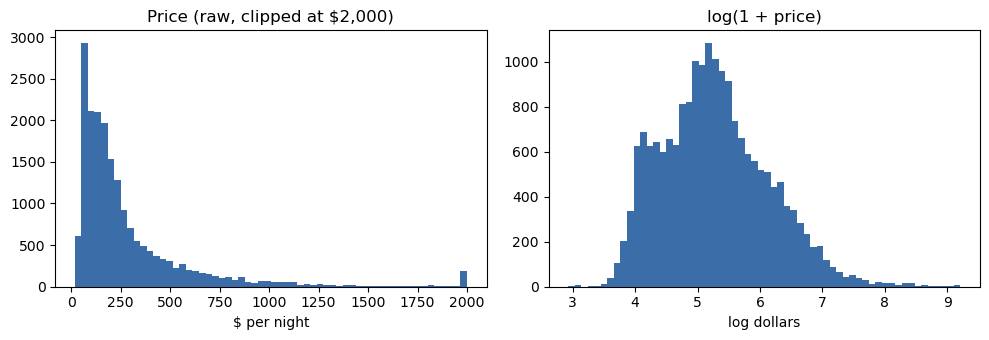

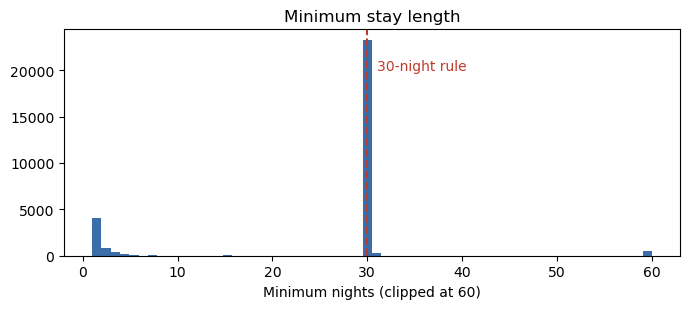

In [26]:
# Figure 2: price before vs after log transform
priced_prices = df_small["price"].dropna()
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(priced_prices.clip(upper=2000), bins=60, color="#3B6EA8")
axes[0].set_title("Price (raw, clipped at $2,000)"); axes[0].set_xlabel("$ per night")
axes[1].hist(np.log1p(priced_prices), bins=60, color="#3B6EA8")
axes[1].set_title("log(1 + price)"); axes[1].set_xlabel("log dollars")
plt.tight_layout(); plt.savefig("fig_price.png"); plt.show()

# Figure 3: minimum nights with the 30-night rule marked
plt.figure(figsize=(7, 3.2))
plt.hist(df_small["minimum_nights"].clip(upper=60), bins=60, color="#3B6EA8")
plt.axvline(30, color="#C0392B", linestyle="--")
plt.text(31, 20000, "30-night rule", color="#C0392B")
plt.xlabel("Minimum nights (clipped at 60)"); plt.title("Minimum stay length")
plt.tight_layout(); plt.savefig("fig_minnights.png"); plt.show()